# T-22 微型感測器校正：共置比對與濕度（初步）

**目的：**⑤ Analytics Engine 的校正步驟要回答兩件事：
1. 微型感測器和國家測站差多少？簡單的線性校正有沒有用？
2. 濕度要用哪一個來源？（T-20 發現臺中微型感測器自己回報的濕度不可靠）

**資料：**2026-10-19 下午到晚上（微型感測器 11:30 起，約 8 小時）。**只有一個下午，所有數字都是初步的。**
**方法：**`src/analytics/calibration.py`。國家測站 1 km 內的微型感測器先各自算小時平均，再取中位數；用留一站交叉驗證評估校正。

In [1]:
import os, sys, glob, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.analytics import calibration as cal

plt.rcParams.update({"font.sans-serif": ["Microsoft JhengHei", "Noto Sans CJK TC", "sans-serif"],
                     "axes.unicode_minus": False, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#52514e", "text.color": "#0b0b0b",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"
FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
CITIES = ["臺中市", "高雄市"]; DAY = "2026-10-19"

def read(path, **kw):
    df = pd.read_csv(path, **kw); df["time"] = pd.to_datetime(df["time"]).dt.tz_convert("Asia/Taipei"); return df

colife = {c: read(ROOT / f"data/raw/colife/{c}/{DAY}.csv.gz", dtype={"station_id": str}) for c in CITIES}
moenv = {c: pd.concat([read(f, dtype={"siteid": str}) for f in sorted(glob.glob(str(ROOT / f"data/raw/moenv/{c}/*.csv.gz")))[-2:]])
            .drop_duplicates(["siteid", "time"]) for c in CITIES}
cwa = {c: read(ROOT / f"data/raw/cwa/{c}/{DAY}.csv.gz", dtype={"station_id": str}) for c in CITIES}
for c in CITIES:
    print(f"{c}: 微型感測器 {colife[c]['time'].min():%H:%M}～{colife[c]['time'].max():%H:%M}；"
          f"氣象站觀測時間 {sorted(cwa[c]['time'].dt.strftime('%H:%M').unique())}")

臺中市: 微型感測器 11:30～19:25；氣象站觀測時間 ['16:00', '17:00', '18:00', '19:00']
高雄市: 微型感測器 11:00～19:30；氣象站觀測時間 ['16:00', '17:00', '18:00', '19:00']


## 1. 國家測站的小時標記慣例

測站 13:00 的值代表 12:00～12:59 還是 13:00～13:59？我們沒有找到可引用的官方說明（待查證），所以用資料比對：
兩種對齊方式下，微型感測器與測站的相關係數。

In [2]:
align = pd.concat([cal.best_alignment(colife[c], moenv[c], r).assign(city=c, radius_km=r)
                   for c in CITIES for r in (1.0, 2.0)])
align.round(3)

,label,n_pairs,r,MAE,city,radius_km
0,end,42,0.257,5.418,臺中市,1.0
1,start,48,0.530,4.508,臺中市,1.0
0,end,42,0.369,4.811,臺中市,2.0
1,start,48,0.670,3.667,臺中市,2.0
0,end,72,0.745,3.071,高雄市,1.0
1,start,83,0.862,4.444,高雄市,1.0
0,end,78,0.752,2.968,高雄市,2.0
1,start,90,0.852,4.224,高雄市,2.0


In [3]:
# 相關係數在兩市、兩種半徑都是 start 較高 → 以 start（13:00 代表 13:00～13:59）為準，之後有官方說明再確認
LABEL = "start"
pairs = pd.concat([cal.collocate(cal.hourly_sensor_means(colife[c], LABEL), moenv[c], radius_km=1.0).assign(city=c)
                   for c in CITIES], ignore_index=True)
summary = pairs.groupby(["city", "sitename"]).agg(小時數=("ref_pm25", "size"), 測站=("ref_pm25", "mean"),
                                                  微型感測器=("sensor_pm25", "mean"), 感測器數=("n_sensors", "median"))
summary.round(1)

小時數    測站  微型感測器  感測器數
city sitename                        
臺中市  大里          8  22.9   18.7  21.0
     忠明          8  20.9   24.1   7.0
     沙鹿          8  22.2   18.8  12.0
     臺灣大道        8  24.6   24.5   8.0
     西屯          8  21.8   18.0   7.0
     豐原          8  26.8   18.7  13.0
高雄市  仁武          7  18.4   16.9   8.0
     前金          8  17.2   15.5  21.0
     前鎮          8  17.6   14.6   8.0
     大寮          7  22.9   17.0  16.0
     小港          8  20.5   15.1  20.0
     左營          7  16.4   13.5   5.0
     復興          8  18.2   14.4  10.0
     林園          7  20.3   15.0  12.0
     楠梓          8  20.6   16.3   9.0
     橋頭          7  19.0   16.2  14.0
     鳳山          8  24.8   16.0   8.0

## 2. 線性校正（留一站交叉驗證）

In [4]:
MODELS = {"不校正": [], "線性": ["sensor_pm25"], "線性＋測站濕度": ["sensor_pm25", "station_rh"]}
cv = pd.concat([cal.leave_one_site_out(pairs[pairs.city == c].reset_index(drop=True), MODELS).assign(city=c)
                for c in CITIES])
cv["MAE 改善"] = 1 - cv["MAE"] / cv.groupby("city")["MAE"].transform("first")
print(cv.round(2).to_string(index=False))
for c in CITIES:
    p = pairs[pairs.city == c]
    print(f"\n{c} 全部資料的係數：", cal.fit(p, ["sensor_pm25"]).round(3).to_dict(),
          cal.fit(p, ["sensor_pm25", "station_rh"]).round(3).to_dict(),
          f"；r = {p['sensor_pm25'].corr(p['ref_pm25']):.2f}；測站濕度 {p['station_rh'].min():.0f}～{p['station_rh'].max():.0f}%")

  model  n  MAE  RMSE  bias city  MAE 改善
    不校正 48 4.51  5.71 -2.74  臺中市    0.00
     線性 48 4.26  5.34  0.18  臺中市    0.05
線性＋測站濕度 48 3.91  4.96  0.18  臺中市    0.13
    不校正 83 4.44  5.26 -4.16  高雄市    0.00
     線性 83 2.36  3.07 -0.00  高雄市    0.47
線性＋測站濕度 83 2.07  2.78 -0.04  高雄市    0.54

臺中市 全部資料的係數： {'intercept': 10.227, 'sensor_pm25': 0.634} {'intercept': 24.398, 'sensor_pm25': 0.53, 'station_rh': -0.182} ；r = 0.53；測站濕度 45～87%

高雄市 全部資料的係數： {'intercept': -2.252, 'sensor_pm25': 1.414} {'intercept': 20.932, 'sensor_pm25': 1.132, 'station_rh': -0.275} ；r = 0.86；測站濕度 53～82%


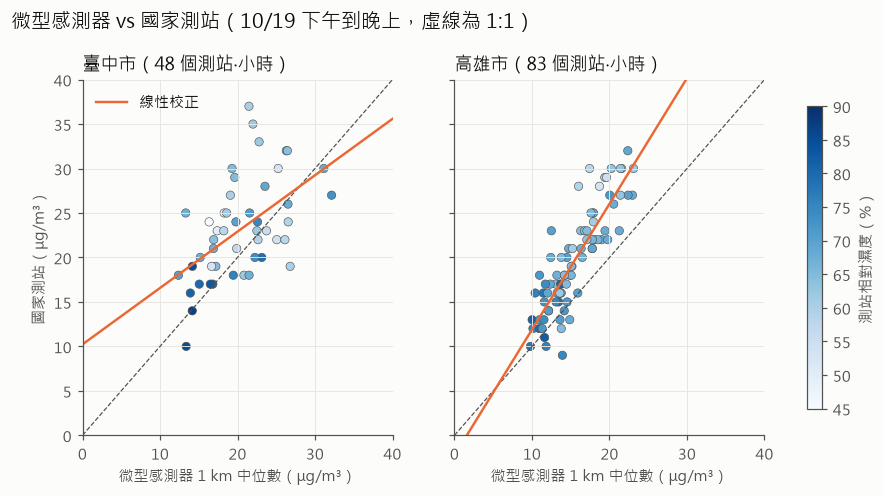

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
lim = [0, max(pairs["ref_pm25"].max(), pairs["sensor_pm25"].max()) + 3]
for ax, c in zip(axes, CITIES):
    p = pairs[pairs.city == c]
    sc = ax.scatter(p["sensor_pm25"], p["ref_pm25"], c=p["station_rh"], cmap="Blues", vmin=45, vmax=90,
                    edgecolor=INK2, linewidth=0.4, s=30)
    ax.plot(lim, lim, color=INK2, lw=0.8, ls="--")
    k = cal.fit(p, ["sensor_pm25"]); x = np.array(lim)
    ax.plot(x, k["intercept"] + k["sensor_pm25"] * x, color=ORANGE, lw=1.6, label="線性校正")
    ax.set_title(f"{c}（{len(p)} 個測站‧小時）", loc="left", fontsize=12); ax.set_xlabel("微型感測器 1 km 中位數（μg/m³）")
    ax.set_xlim(lim); ax.set_ylim(lim)
axes[0].set_ylabel("國家測站（μg/m³）"); axes[0].legend(frameon=False, loc="upper left")
fig.colorbar(sc, ax=axes, label="測站相對濕度（%）", shrink=0.85)
fig.suptitle("微型感測器 vs 國家測站（10/19 下午到晚上，虛線為 1:1）", x=0.06, y=1.03, ha="left", fontsize=13)
fig.savefig(FIG / "t22_fig1_collocation.png", dpi=160, bbox_inches="tight")

## 3. 三種濕度來源的比較

In [6]:
near = pd.concat([cal.nearest_weather(moenv[c], cwa[c]) for c in CITIES])
w = pd.concat(cwa.values())[["station_id", "time", "rh"]].rename(columns={"station_id": "cwa_id", "rh": "cwa_rh"})
w["time"] = w["time"].dt.floor("h")
rh = pairs.merge(near, on="siteid").merge(w, on=["cwa_id", "time"], how="left")
rows = []
for c in CITIES:
    r = rh[rh.city == c]
    for name, col in [("微型感測器自己回報", "sensor_rh"), ("最近的氣象站", "cwa_rh")]:
        ok = r[[col, "station_rh"]].dropna()
        rows.append({"city": c, "濕度來源": name, "n": len(ok), "平均（%）": ok[col].mean(),
                     "測站平均（%）": ok["station_rh"].mean(), "與測站差的平均絕對值": (ok[col] - ok["station_rh"]).abs().mean()})
rh_table = pd.DataFrame(rows); print(rh_table.round(1).to_string(index=False))
print("\n測站到最近氣象站的距離（km）：", near["cwa_km"].describe().round(1).to_dict())

city      濕度來源  n  平均（%）  測站平均（%）  與測站差的平均絕對值
 臺中市 微型感測器自己回報 48   99.8     66.1        33.6
 臺中市    最近的氣象站 18   75.2     75.8         5.7
 高雄市 微型感測器自己回報 83   65.4     68.4         4.0
 高雄市    最近的氣象站 32   73.5     73.2         3.5

測站到最近氣象站的距離（km）： {'count': 18.0, 'mean': 2.1, 'std': 1.1, 'min': 0.0, '25%': 1.5, '50%': 2.1, '75%': 2.8, 'max': 4.0}


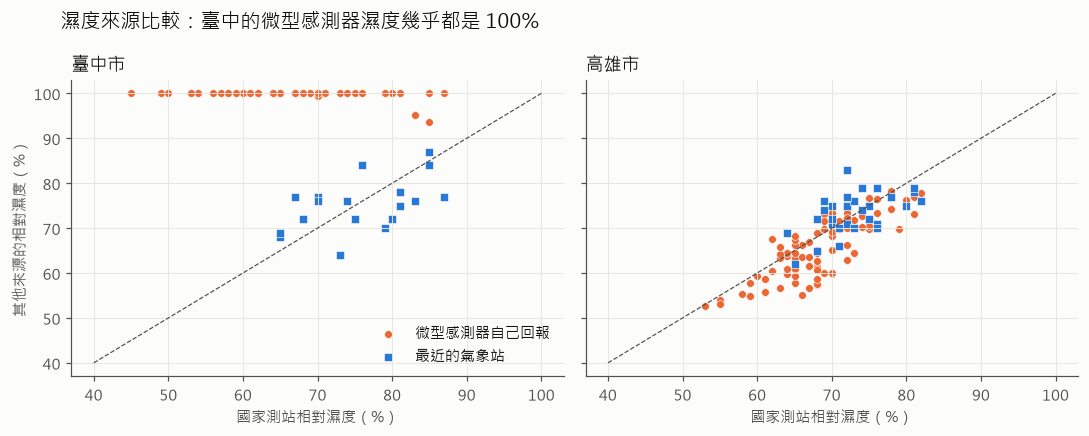

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, c in zip(axes, CITIES):
    r = rh[rh.city == c]
    ax.scatter(r["station_rh"], r["sensor_rh"], color=ORANGE, s=26, label="微型感測器自己回報", edgecolor="white", linewidth=0.4)
    ax.scatter(r["station_rh"], r["cwa_rh"], color=BLUE, s=26, marker="s", label="最近的氣象站", edgecolor="white", linewidth=0.4)
    ax.plot([40, 100], [40, 100], color=INK2, lw=0.8, ls="--")
    ax.set_title(c, loc="left", fontsize=12); ax.set_xlabel("國家測站相對濕度（%）")
axes[0].set_ylabel("其他來源的相對濕度（%）"); axes[0].legend(frameon=False, loc="lower right")
fig.suptitle("濕度來源比較：臺中的微型感測器濕度幾乎都是 100%", x=0.06, ha="left", fontsize=13)
fig.tight_layout(); fig.savefig(FIG / "t22_fig2_humidity_sources.png", dpi=160)

## 結論（初步，只有一個下午）

見 `coordination/reports/T-22.md`。重點：
- 線性校正在留一站交叉驗證下能降低誤差；加入**測站濕度**再降低一些，但一個下午裡濕度與時段高度相關，濕度係數**不能解釋成濕度效應**。
- 臺中微型感測器回報的濕度幾乎都是 100%，再次確認不能用；氣象站濕度與測站濕度接近，可以作為沒有測站地方的濕度來源。
- 需要多天資料（涵蓋不同濕度、不同污染程度）才能得到可用的校正係數。